In [51]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pyrosm import OSM
import xarray as xr
import xrspatial
from rasterio.enums import Resampling

## Find Bihor limit

(np.float64(221646.16229499524),
 np.float64(338532.37580499554),
 np.float64(539140.2710500018),
 np.float64(688467.0299499993))

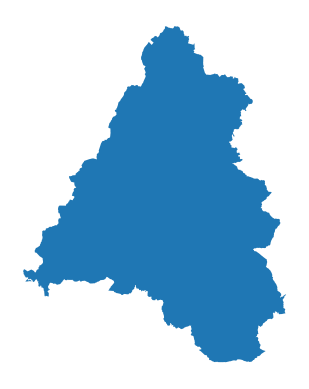

In [15]:
path = r"raw_data/Judete.gpkg"
judete_gdf = gpd.read_file(path)
bihor = judete_gdf.loc[judete_gdf["name"] == "Bihor"]
bihor.plot()
plt.axis('off')

In [16]:
# Transform to Stereo 70 projection 
bihor = bihor.to_crs("EPSG:3844")

In [17]:
bihor.to_file(r"data/bihor.gpkg", driver="GPKG")

## Reprojecting and clipping

### 1. Roads, power lines, places

In [18]:
# in download_data_osm.ipynb were downloaded and cliped

In [19]:
gpd.read_file("data/roads.gpkg").to_crs("EPSG:3844").to_file("data/roads.gpkg")
gpd.read_file("data/lines.gpkg").to_crs("EPSG:3844").to_file("data/lines.gpkg")
gpd.read_file("data/substations.gpkg").to_crs("EPSG:3844").to_file("data/substations.gpkg")
gpd.read_file("data/places.gpkg").to_crs("EPSG:3844").to_file("data/places.gpkg")

### 2. Protected areas

In [20]:
path = r"raw_data/Arii_protejate_europa.gpkg"
gpd.list_layers(path)

,name,geometry_type
0,NaturaSite_polygon,Unknown
1,BIOREGION,NaN
2,DESIGNATIONSTATUS,NaN
3,HABITATS,NaN
4,HABITATCLASS,NaN
5,NATURA2000SITES,NaN
6,OTHERSPECIES,NaN
7,METADATA,NaN
8,IMPACT,NaN
9,MANAGEMENT,NaN


In [21]:
arii_protejate_europa = gpd.read_file(path, layer="NaturaSite_polygon")

In [22]:
arii_protejate_europa = arii_protejate_europa.to_crs("EPSG:3844")

In [23]:
arii_protejate_bihor = gpd.clip(arii_protejate_europa, bihor)

In [24]:
arii_protejate_bihor_diss = arii_protejate_bihor.dissolve()

In [25]:
arii_protejate_bihor_diss.to_file(r"data/arii_protejate_bihor.gpkg", driver="GPKG")

### 3. Calculate Slope (DEM)

In [52]:
dem_file = xr.open_dataset("raw_data/dem.tif", engine="rasterio")

In [53]:
dem_file = dem_file.rio.reproject("EPSG:3844", resolution=30, resampling=Resampling.bilinear)

In [62]:
dem_file.rio.resolution()

(30.0, -30.0)

In [54]:
dem_file = dem_file.rio.clip(geometries=bihor.geometry)

In [55]:
dem_file = dem_file.squeeze("band", drop=True)

In [56]:
dem_file = dem_file.rename({"band_data": "elevation"})

In [57]:
dem_file["slope"] = xrspatial.slope(dem_file["elevation"])

Text(0.5, 1.0, 'Panta pentru Bihor')

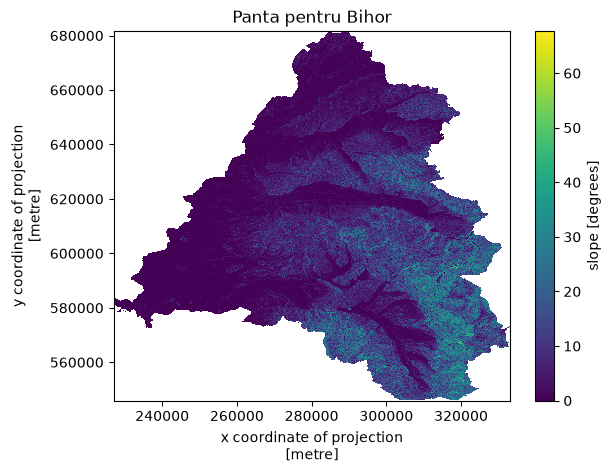

In [58]:
dem_file["slope"].plot(cmap="viridis")
plt.title("Panta pentru Bihor")

In [59]:
dem_file["slope"].rio.to_raster("data/slope.tif")

In [34]:
import leafmap

m = leafmap.Map()
m.add_raster("data/slope.tif", colormap="viridis", layer_name="Panta")
m

Map(center=[46.9855385, 22.0987], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', …

### 4. Land use Corine

In [35]:
land_use = gpd.read_file(r"raw_data\clc_2018(land use Romania)\Romania_18_st.shp")

In [36]:
land_use = land_use.to_crs("EPSG:3844")
land_use_bihor = land_use.clip(bihor)

In [37]:
land_use_bihor.to_file("data/land_use_bihor.gpkg", driver="GPKG")

### 5. PVOUT

In [63]:
pvout = xr.open_dataset(r"raw_data\PVOUT.tif")
pvout = pvout.rio.reproject("EPSG:3844")

In [64]:
pvout_bihor = pvout.rio.clip(geometries=bihor.geometry)

In [65]:
pvout_bihor = pvout_bihor.squeeze("band", drop=True)
pvout_bihor = pvout_bihor.rename({"band_data": "band"})

In [72]:
pvout_bihor = pvout_bihor.rio.reproject_match(dem_file["slope"], resampling=Resampling.bilinear)
print("New resolution:", pvout_bihor.rio.resolution())
print("New CRS:", pvout_bihor.rio.crs)

New resolution: (30.0, -30.0)
New CRS: EPSG:3844


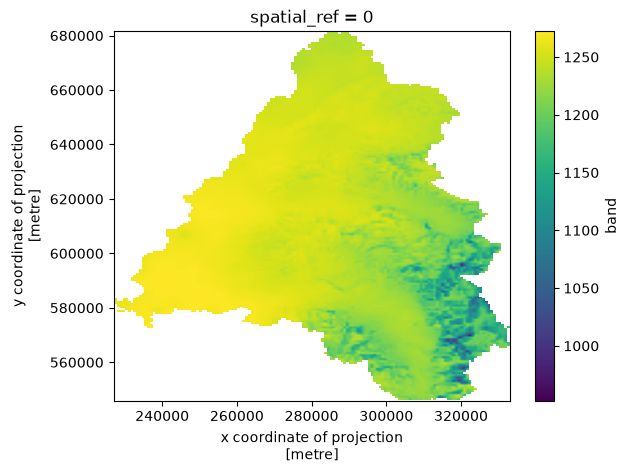

In [76]:
pvout_bihor["band"].plot(cmap="viridis")

In [77]:
pvout_bihor.rio.to_raster("data/PVOUT_bihor.tif")